In [3]:
import os 
import torch
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
%matplotlib inline 

In [4]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

DATA_DIR = "../data"
CATEGORIES = ["airplane", "bicycle", "cat", "car", "dog", "fish", "house", "sun", "tree" , "umbrella"]

N_PER_CLASS = 10000
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


In [5]:
X_list, y_list = [], [] 

for idx, name in enumerate(CATEGORIES):
    path = os.path.join(DATA_DIR, f"{name}.npy")
    arr = np.load(path, mmap_mode="r")[:N_PER_CLASS]
    X_list.append(np.array(arr))
    y_list.append(np.full(len(arr), idx))
    print(f"{name:10s} -> label {idx}, {len(arr)} samples")
X = np.concatenate(X_list)
y = np.concatenate(y_list)
print(X.shape, y.shape,X.dtype)


airplane   -> label 0, 10000 samples
bicycle    -> label 1, 10000 samples
cat        -> label 2, 10000 samples
car        -> label 3, 10000 samples
dog        -> label 4, 10000 samples
fish       -> label 5, 10000 samples
house      -> label 6, 10000 samples
sun        -> label 7, 10000 samples
tree       -> label 8, 10000 samples
umbrella   -> label 9, 10000 samples
(100000, 784) (100000,) uint8


In [ ]:
X = X.astype(np.float32) / 255.0 ## because min was 0 and max was 255, we have to normalize it 
X = X.reshape(-1, 1, 28 , 28) ## -1 means all images, 1 means one channel, 28, 28 means height and width 
print(X.shape, X.min(), X.max()) 

(100000, 1, 28, 28) 0.0 1.0


In [17]:
X_train, X_test , y_train , y_test = train_test_split(X, y, test_size = 0.2, stratify = y , random_state = 42)
print(X_train.shape, X_test.shape)
print("train counts: " , np.bincount(y_train))
print("test counts: ", np.bincount(y_test))

(80000, 1, 28, 28) (20000, 1, 28, 28)
train counts:  [8000 8000 8000 8000 8000 8000 8000 8000 8000 8000]
test counts:  [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]


In [12]:
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long()) # .long() because CrossEntropyLoss wants int64 class indices
test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test).long())

train_loader = DataLoader(train_ds , batch_size = 128, shuffle = True)
test_loader = DataLoader(test_ds , batch_size = 256, shuffle = False)

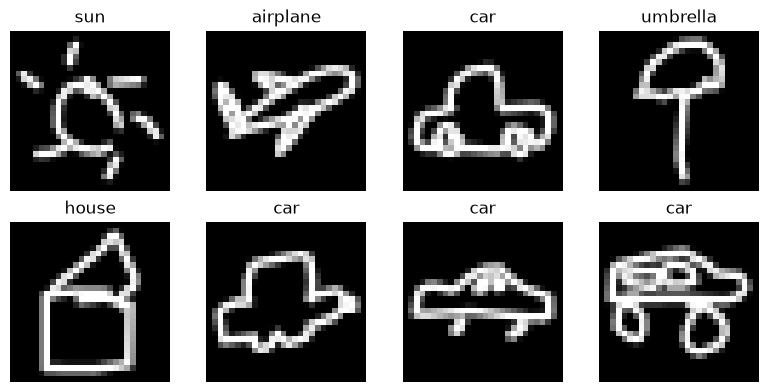

In [15]:
xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax, img, label in zip(axes.flat, xb[:8], yb[:8]):
    ax.imshow(img.squeeze(), cmap="gray")   # squeeze: (1,28,28) -> (28,28) for imshow
    ax.set_title(CATEGORIES[label])
    ax.axis("off")
plt.tight_layout()

In [20]:
from torch import nn


class DoodleCNN(nn.Module):
    def __init__(self, num_classes = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,32, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64,128, kernel_size = 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128 , num_classes)
        )

    def forward(self, x):
            return self.classifier(self.features(x))
model = DoodleCNN(len(CATEGORIES)).to(device)

dummy = torch.zeros(4, 1, 28, 28, device=device)
print(model(dummy).shape)                                    # expect torch.Size([4, 10])
print(sum(p.numel() for p in model.parameters()), "params") 

torch.Size([4, 10])
241546 params


In [21]:
criterion = nn.CrossEntropyLoss()                      # expects raw logits + int64 labels
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, loader):
    model.train()                                       # enables dropout
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)           # data must be on same device as model

        optimizer.zero_grad()                           # 1. clear old gradients
        logits = model(xb)                              # 2. forward
        loss = criterion(logits, yb)                    # 3. how wrong?
        loss.backward()                                 # 4. compute gradients
        optimizer.step()                                # 5. nudge weights

        total_loss += loss.item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n

@torch.no_grad()                                        # no gradient bookkeeping -> faster, less memory
def evaluate(model, loader):
    model.eval()                                        # disables dropout
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n

EPOCHS = 5
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    te_loss, te_acc = evaluate(model, test_loader)
    print(f"epoch {epoch}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"test loss {te_loss:.3f} acc {te_acc:.3f}")

epoch 1: train loss 0.629 acc 0.796 | test loss 0.327 acc 0.894
epoch 2: train loss 0.312 acc 0.901 | test loss 0.258 acc 0.916
epoch 3: train loss 0.258 acc 0.918 | test loss 0.232 acc 0.924
epoch 4: train loss 0.225 acc 0.926 | test loss 0.222 acc 0.926
epoch 5: train loss 0.203 acc 0.933 | test loss 0.218 acc 0.930


In [22]:
os.makedirs("../models", exist_ok=True)
torch.save(model.state_dict(), "../models/doodle_cnn.pt")